## Identificação da equipe

- **Número da sala:** 4
- **Integrantes:** Mauro Roberto Barbosa Cahu ([e-mail removido antes da publicação]), Pedro Paulo Sant'Anna Belo Ramos ([e-mail removido antes da publicação]), Renato Vasconcellos Bittencourt Neto ([e-mail removido antes da publicação]), Vinicius Dantas Batista da Silva ([e-mail removido antes da publicação])
- **Dataset escolhido:** Wine — UCI Machine Learning Repository
- **Link do dataset:** https://archive.ics.uci.edu/dataset/109/wine

178 vinhos com 13 atributos químicos em escalas diferentes.


## 1. **Carregar os dados**

In [76]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo

ds = fetch_ucirepo(id=109)  # Wine
df = ds.data.features.assign(target=ds.data.targets)
print(df.shape)
df.head()

(178, 14)


,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline,target
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


## 2. **Explorando os dados**

In [77]:
import pandas as pd

In [78]:
df.shape

(178, 14)

In [79]:
df.dtypes

,0
Alcohol,float64
Malicacid,float64
Ash,float64
Alcalinity_of_ash,float64
Magnesium,int64
Total_phenols,float64
Flavanoids,float64
Nonflavanoid_phenols,float64
Proanthocyanins,float64
Color_intensity,float64


In [80]:
df.describe()

,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,1.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,1.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,1.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,2.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,3.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,3.000000


In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Alcohol                       178 non-null    float64
 1   Malicacid                     178 non-null    float64
 2   Ash                           178 non-null    float64
 3   Alcalinity_of_ash             178 non-null    float64
 4   Magnesium                     178 non-null    int64  
 5   Total_phenols                 178 non-null    float64
 6   Flavanoids                    178 non-null    float64
 7   Nonflavanoid_phenols          178 non-null    float64
 8   Proanthocyanins               178 non-null    float64
 9   Color_intensity               178 non-null    float64
 10  Hue                           178 non-null    float64
 11  0D280_0D315_of_diluted_wines  178 non-null    float64
 12  Proline                       178 non-null    int64  
 13  targe

In [82]:
df.duplicated().sum()

np.int64(0)

Dataset sem duplicadas e sem valores nulos. Hora de investigar os dados

## 3. **Desvendando outliers**


In [83]:
def resumo_outliers(df):
    resultado = []

    for coluna in df.select_dtypes(include='number').columns:
        Q1 = df[coluna].quantile(0.25)
        Q3 = df[coluna].quantile(0.75)
        IQR = Q3 - Q1

        limite_inf = Q1 - 1.5 * IQR
        limite_sup = Q3 + 1.5 * IQR

        n_outliers = df[(df[coluna] < limite_inf) | (df[coluna] > limite_sup)].shape[0]
        pct = round(n_outliers / len(df) * 100, 2)

        resultado.append({
            'coluna': coluna,
            'outliers': n_outliers,
            'percentual': pct,
            'limite_inferior': round(limite_inf, 2),
            'limite_superior': round(limite_sup, 2)
        })

    return pd.DataFrame(resultado).sort_values('outliers', ascending=False)

resumo_outliers(df)

,coluna,outliers,percentual,limite_inferior,limite_superior
4,Magnesium,4,2.25,59.50,135.50
3,Alcalinity_of_ash,4,2.25,10.75,27.95
9,Color_intensity,4,2.25,-1.25,10.67
2,Ash,3,1.69,1.69,3.08
1,Malicacid,3,1.69,-0.62,5.30
8,Proanthocyanins,2,1.12,0.20,3.00
10,Hue,1,0.56,0.28,1.63
0,Alcohol,0,0.00,10.39,15.65
5,Total_phenols,0,0.00,0.16,4.39
7,Nonflavanoid_phenols,0,0.00,0.02,0.69


In [84]:
df_wine = df.copy()

In [85]:
from sklearn.preprocessing import StandardScaler

colunas = [
    "Alcohol",
    "Malicacid",
    "Ash",
    "Alcalinity_of_ash",
    "Magnesium",
    "Total_phenols",
    "Flavanoids",
    "Nonflavanoid_phenols",
    "Proanthocyanins",
    "Color_intensity",
    "Hue",
    "0D280_0D315_of_diluted_wines",
    "Proline"
]

scaler = StandardScaler()

df_wine[colunas] = scaler.fit_transform(df_wine[colunas])

In [86]:
import plotly.express as px

# Substitua 'df' pelo seu DataFrame contendo as 14 colunas numéricas
fig = px.box(df_wine, title='Boxplot das 14 Colunas')
fig.show()

In [87]:
df.head()

,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline,target
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


Após a verficação de quantos dados temos de outliers, considerando os métodos dos quartis, investigamos os mesmos pelo boxplot. Decidimos normalizar os dados, para investigar na mesma escala.

Foi decidido, pelo grupo, **manter os outliers**, visto que não temos nenhum dado muito discrepante dos dados

**Proximos passos:**

1. Escolher um vinho aleatorio e trazer um ranking de vinhos mais proximos para indicar para o cliente - melhor opção ?

## 4. **Medidas de distância e similaridade**

decidido usar o método euclidiano e o de manhatan por estarmos lidando apenas com dados numéricos

Padronizar os dados devido a coluna *proline* - valores muito discrepantes dos demais

In [88]:
from sklearn.preprocessing import StandardScaler

# Colunas numéricas sem o target
features = df.drop(columns=['target']).columns.tolist()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

df_scaled = pd.DataFrame(X_scaled, columns=features)
df_scaled['target'] = df['target'].values
df_scaled.insert(0, 'vinho_id', range(len(df_scaled)))

Funções de distância

In [89]:
import numpy as np

def distancia_euclidiana(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return np.sqrt(np.sum((a - b) ** 2))

def distancia_manhattan(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return np.sum(np.abs(a - b))

Função de raking de similares

In [90]:
def ranking_similares(df, referencia_idx, colunas, funcao_distancia, top_n=5):
    ref = df.loc[referencia_idx, colunas].values.astype(float)  # pega o vinho de referência

    resultado = []
    for idx, row in df.iterrows():          # percorre todos os vinhos
        if idx == referencia_idx:
            continue                         # pula o próprio vinho de referência
        ponto = row[colunas].values.astype(float)
        resultado.append({
            'vinho_id': idx,
            'target': row['target'],
            'distancia': round(funcao_distancia(ref, ponto), 4)  # calcula distância
        })

    return pd.DataFrame(resultado).sort_values('distancia').reset_index(drop=True).head(top_n)

Função euclidiana

In [124]:
# 4 colunas que caracterizam bem o perfil do vinho
colunas_escolhidas = ['Alcohol', 'Flavanoids', 'Color_intensity', 'Proline']

# Vinho aleatório
vinho_ref = np.random.randint(0, len(df_scaled))
print(f'Vinho de referência: índice {vinho_ref} | Classe: {df_scaled.loc[vinho_ref, "target"]}')

# Top 10 mais parecidos com base nessas 4 colunas
ranking_similares(
    df_scaled,
    referencia_idx=vinho_ref,
    colunas=colunas_escolhidas,
    funcao_distancia=distancia_euclidiana,
    top_n=10
)

Vinho de referência: índice 68 | Classe: 2


,vinho_id,target,distancia
0,62,2.0,0.7928
1,130,3.0,0.8136
2,145,3.0,0.9001
3,143,3.0,1.0297
4,72,2.0,1.0830
5,83,2.0,1.1271
6,101,2.0,1.1378
7,92,2.0,1.1544
8,142,3.0,1.2082
9,163,3.0,1.2138


Funcao manhattan

In [125]:
# 4 colunas que caracterizam bem o perfil do vinho
colunas_escolhidas = ['Alcohol', 'Flavanoids', 'Color_intensity', 'Proline']

# Vinho aleatório
vinho_ref = np.random.randint(0, len(df_scaled))
print(f'Vinho de referência: índice {vinho_ref} | Classe: {df_scaled.loc[vinho_ref, "target"]}')

# Top 10 mais parecidos com base nessas 4 colunas
ranking_similares(
    df_scaled,
    referencia_idx=vinho_ref,
    colunas=colunas_escolhidas,
    funcao_distancia=distancia_manhattan,
    top_n=10
)

Vinho de referência: índice 146 | Classe: 3


,vinho_id,target,distancia
0,142,3.0,1.1977
1,165,3.0,1.3942
2,143,3.0,1.4292
3,138,3.0,1.4938
4,161,3.0,1.7234
5,140,3.0,2.0530
6,139,3.0,2.1116
7,141,3.0,2.2681
8,137,3.0,2.2903
9,162,3.0,2.3211


Euclidiana Vs Manhattan

In [126]:
print('===Euclidiana===\n')
print(ranking_similares(df_scaled,156,colunas_escolhidas,distancia_euclidiana))

print('\n===Manhattan===\n')
print(ranking_similares(df_scaled,156,colunas_escolhidas,distancia_manhattan))

===Euclidiana===

   vinho_id  target  distancia
0       177     3.0     0.4527
1       164     3.0     0.5232
2       169     3.0     0.7676
3       172     3.0     0.7687
4       150     3.0     0.8740

===Manhattan===

   vinho_id  target  distancia
0       177     3.0     0.7655
1       164     3.0     0.9012
2       168     3.0     1.3424
3       169     3.0     1.3723
4       172     3.0     1.3975


In [127]:
from sklearn.decomposition import PCA
import plotly.express as px

# Reduz as 4 colunas para 2 dimensões para visualizar
pca = PCA(n_components=2)
coords = pca.fit_transform(df_scaled[colunas_escolhidas])

df_plot = pd.DataFrame({
    'x': coords[:, 0],
    'y': coords[:, 1],
    'target': df_scaled['target'].astype(str),
    'vinho_id': df_scaled.index
})

# Pega os top 10 de cada métrica
top_euclidiana = ranking_similares(df_scaled, vinho_ref, colunas_escolhidas, distancia_euclidiana, top_n=10)['vinho_id'].tolist()
top_manhattan = ranking_similares(df_scaled, vinho_ref, colunas_escolhidas, distancia_manhattan, top_n=10)['vinho_id'].tolist()

# Classifica cada ponto
def classificar(idx):
    if idx == vinho_ref:
        return 'Referência'
    elif idx in top_euclidiana and idx in top_manhattan:
        return 'Top 10 Ambos'
    elif idx in top_euclidiana:
        return 'Top 10 Euclidiana'
    elif idx in top_manhattan:
        return 'Top 10 Manhattan'
    else:
        return 'Demais vinhos'

df_plot['grupo'] = df_plot['vinho_id'].apply(classificar)

# Tamanho das bolinhas por grupo
tamanho = df_plot['grupo'].map({
    'Referência': 25,
    'Top 10 Ambos': 18,
    'Top 10 Euclidiana': 15,
    'Top 10 Manhattan': 15,
    'Demais vinhos': 8
})

# Cores por grupo
cores = {
    'Referência': 'red',
    'Top 10 Ambos': 'gold',
    'Top 10 Euclidiana': 'blue',
    'Top 10 Manhattan': 'green',
    'Demais vinhos': 'lightgrey'
}

fig = px.scatter(
    df_plot,
    x='x',
    y='y',
    color='grupo',
    color_discrete_map=cores,
    size=tamanho,
    hover_data=['vinho_id', 'target'],
    title=f'Proximidade dos Vinhos — Referência: índice {vinho_ref}',
    labels={'x': 'Componente 1 (PCA)', 'y': 'Componente 2 (PCA)'}
)

fig.show()

* Nota-se que por a função euclidiana **elevar ao quadrado**, penaliza **muito** vinhos com uma coluna muito diferente. o que empurra os vinhos para mais longe no grafico

* A Manhattan us ao valor **absoluto**, distribui a distância igualmente entre as colunas. Vinhos com pequenas diferenças em várias clunas ficam **mais próximos**

## 5. **Clusterização - agrupamento hierárquico**

Dado o gráfico de dispersão dos dados que temos aima, foi escolhido usar o método **average**, por ser o mais utilizado e garantir que ele faça mais agrupamentos e não conflita grupos com vinhos muito próximos

In [95]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
import matplotlib.pyplot as plt

Usado o df_scaled por normalizar o proline (valores ~1000 dominaria completamente as distâncias)

In [152]:
# Usando  4 colunas novas
colunas_escolhidas = ['Alcohol', 'Total_phenols', 'Nonflavanoid_phenols', 'Proline']

# Extrai só as colunas escolhidas já padronizadas
X = df_scaled[colunas_escolhidas].values

print(f'Shape dos dados: {X.shape}')
print(f'Colunas usadas: {colunas_escolhidas}')

Shape dos dados: (178, 4)
Colunas usadas: ['Alcohol', 'Total_phenols', 'Nonflavanoid_phenols', 'Proline']


Calculado o linkage com o método average

In [153]:
# Calculando o linkage com método average
Z = linkage(X, method='average', metric='euclidean')

print(f'Shape do linkage: {Z.shape}')
print(f'Primeiras linhas do linkage:')
print(Z[:5])

Shape do linkage: (177, 4)
Primeiras linhas do linkage:
[[1.07000000e+02 1.71000000e+02 8.57737116e-02 2.00000000e+00]
 [0.00000000e+00 4.50000000e+01 1.87835136e-01 2.00000000e+00]
 [1.45000000e+02 1.75000000e+02 1.98779137e-01 2.00000000e+00]
 [1.53000000e+02 1.55000000e+02 2.00221243e-01 2.00000000e+00]
 [8.90000000e+01 1.29000000e+02 2.20571070e-01 2.00000000e+00]]


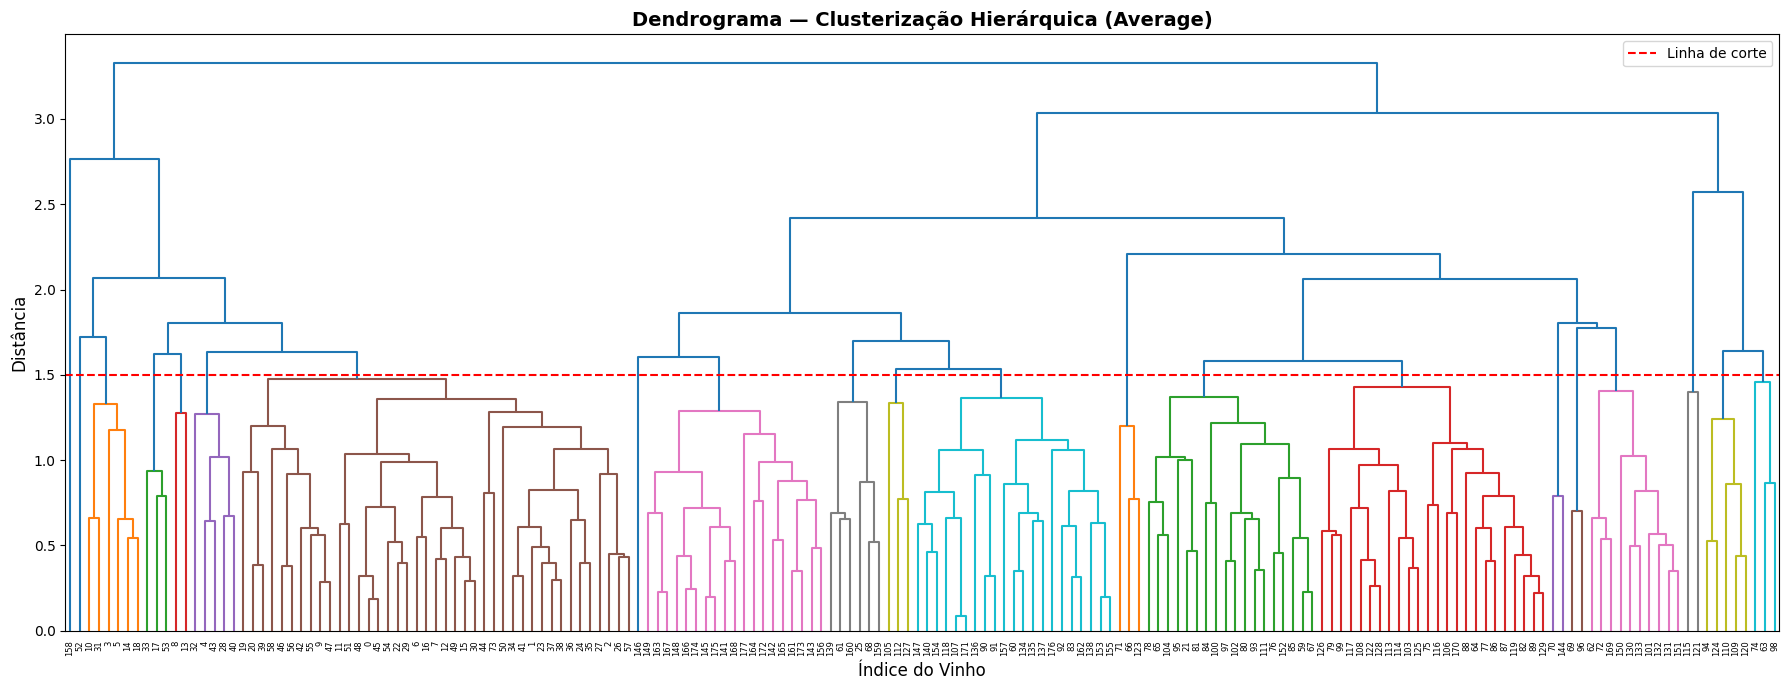

In [149]:
fig, ax = plt.subplots(figsize=(18, 7))

dendrogram(
    Z,
    ax=ax,
    leaf_rotation=90,
    leaf_font_size=6,
    color_threshold=1.5    # linha de corte visual
)

ax.set_title('Dendrograma — Clusterização Hierárquica (Average)', fontsize=14, fontweight='bold')
ax.set_xlabel('Índice do Vinho', fontsize=12)
ax.set_ylabel('Distância', fontsize=12)
ax.axhline(y=1.5, color='red', linestyle='--', linewidth=1.5, label='Linha de corte')
ax.legend()

plt.tight_layout()
plt.show()

decidindo o numero de clusters

In [150]:
ultimas_fusoes = pd.DataFrame(
    Z[-10:, 2],
    columns=['distancia'],
    index=range(len(Z)-10, len(Z))
)

ultimas_fusoes['salto'] = ultimas_fusoes['distancia'].diff()

print('Últimas 10 fusões:')
print(ultimas_fusoes.round(4))

Últimas 10 fusões:
     distancia   salto
167     1.8039     NaN
168     1.8609  0.0570
169     2.0598  0.1988
170     2.0684  0.0087
171     2.2086  0.1402
172     2.4177  0.2091
173     2.5700  0.1523
174     2.7641  0.1941
175     3.0329  0.2688
176     3.3292  0.2964


Os saltos são graduais e crescentes ao longo das fusões, sem um ponto
de ruptura claro. Os maiores saltos ocorrem nas fusões 175 (0.2688) e
176 (0.2964), sugerindo **2 ou 3 clusters** como opções mais razoáveis.
Optamos pelo corte em 3.0, que preserva **3 clusters** alinhados com
as 3 classes reais do dataset Wine.

Escolhendo o corte de 2.8 para gerar 3 cluesters

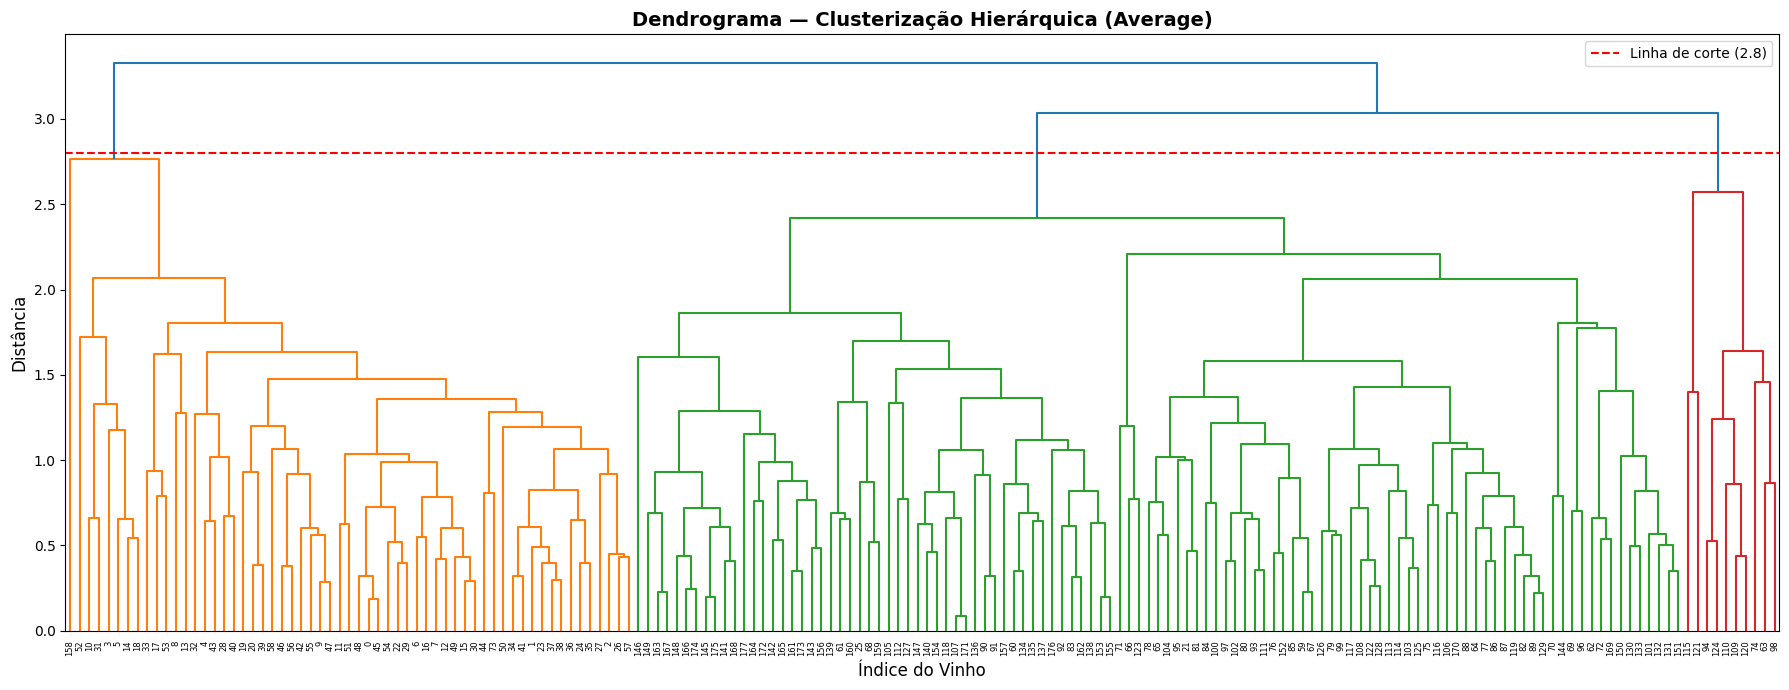

In [154]:
fig, ax = plt.subplots(figsize=(18, 7))

dendrogram(
    Z,
    ax=ax,
    leaf_rotation=90,
    leaf_font_size=6,
    color_threshold=2.8
)

ax.set_title('Dendrograma — Clusterização Hierárquica (Average)', fontsize=14, fontweight='bold')
ax.set_xlabel('Índice do Vinho', fontsize=12)
ax.set_ylabel('Distância', fontsize=12)
ax.axhline(y=2.8, color='red', linestyle='--', linewidth=1.5, label='Linha de corte (2.8)')
ax.legend()

plt.tight_layout()
plt.show()

* Ao compararmos o corte 1.5 com o corte de 2.8, notamos que o corte
  com mais grupos teria poucos vinhos por cluster, dificultando a
  extração de padrões interpretáveis

* O corte em 1.5 dividiria os clusters por diferenças pequenas e
  graduais — o que os dados das novas colunas confirmam, já que os
  saltos entre fusões são todos menores que 0.30

* O dataset possui 3 classes de vinhos reais (target), o que orienta
  a escolha pelo corte em 2.8 gerando 3 clusters

* O corte em 1.5 só faria sentido se o objetivo fosse identificar
  microgrupos de vinhos muito similares entre si, o que não é o caso

Hora de cortar o dendograma e atribuir os cluesters

In [155]:
# Recalcula o linkage com as novas colunas
X = df_scaled[colunas_escolhidas].values
Z = linkage(X, method='average', metric='euclidean')

# Corta o dendrograma em 3.0 definindo 3 clusters
clusters = fcluster(Z, t=3.0, criterion='distance')

# Adiciona os clusters ao dataframe
df_scaled['cluster_id'] = clusters
df['cluster_id'] = clusters

# Confere quantos vinhos ficaram em cada cluster
print('Distribuição dos clusters:')
print(df_scaled['cluster_id'].value_counts().sort_index())

# Compara com o target real
print('\nComparação com target real:')
print(pd.crosstab(df['cluster_id'], df['target']))

Distribuição dos clusters:
cluster_id
1     59
2    109
3     10
Name: count, dtype: int64

Comparação com target real:
target       1   2   3
cluster_id            
1           57   1   1
2            2  60  47
3            0  10   0


**Comparação entre Clusters e Classes Reais (Target)**

* O **Cluster 1** capturou com alta precisão os vinhos do Target 1
  (57 de 59 vinhos), com apenas 2 classificações incorretas

* O **Cluster 2** agrupou a maior parte dos vinhos, misturando
  Target 2 (60 vinhos) e Target 3 (47 vinhos) — indicando que as
  colunas escolhidas não separam bem essas duas classes entre si

* O **Cluster 3** isolou 10 vinhos do Target 2, sugerindo que
  existe um subgrupo dentro do Target 2 com perfil químico distinto
  nas variáveis Alcohol, Total_phenols, Nonflavanoid_phenols e Proline

* A principal limitação das colunas escolhidas está na separação
  entre Target 2 e Target 3 — que ficaram agrupados no mesmo cluster.
  Colunas como Flavanoids e Color_intensity provavelmente
  contribuiriam para separar esses dois grupos

O modelo identificou corretamente o Target 1, mas não conseguiu
separar Target 2 e Target 3 com as colunas escolhidas — o que
reforça que a escolha das variáveis impacta diretamente
a qualidade da clusterização.

**Visualizando os clusters**

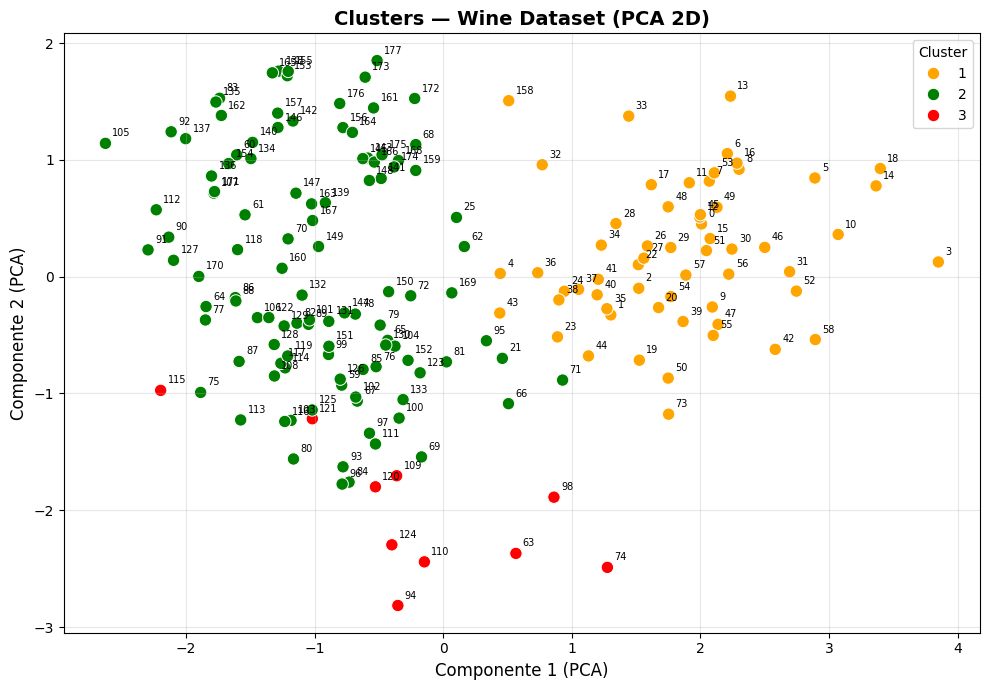

In [159]:
# Cores iguais ao dendrograma
cores_clusters = {
    '1': 'orange',
    '2': 'green',
    '3': 'red'
}

fig, ax = plt.subplots(figsize=(10, 7))

sns.scatterplot(
    data=df_plot,
    x='x',
    y='y',
    hue='cluster_id',
    palette=cores_clusters,
    s=80,
    ax=ax
)

for i, row in df_plot.iterrows():
    ax.annotate(
        row['vinho_id'],
        (row['x'], row['y']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=7
    )

ax.set_title('Clusters — Wine Dataset (PCA 2D)', fontsize=14, fontweight='bold')
ax.set_xlabel('Componente 1 (PCA)', fontsize=12)
ax.set_ylabel('Componente 2 (PCA)', fontsize=12)
ax.legend(title='Cluster')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()